# Where does a learned inverse-design model fail, and can we see it coming?

**Author:** Jahid Hasan Jony · short self-directed exploration on [EngiBench](https://engibench.ethz.ch) (IDEAL Lab, ETH Zurich)

Inverse-design models map a requested condition (volume fraction, load position, ...) straight to a design, skipping the expensive optimizer. Benchmarks usually report average quality. This notebook asks two reliability questions on **Beams2D** (2D topology optimization of an MBB beam):

1. **Where does it fail?** Simulate every generated design and compare its compliance to the optimized ground truth, **per condition**, not just on average. Which regions of condition space produce the worst designs, and how often are constraints violated?
2. **Can we see it coming, before simulating?** Two cheap warning signals: **ensemble disagreement** (5 models trained with different seeds) and **distance to the nearest training condition**. How well do they flag the worst designs (AUROC)?

Model: a small conditional CNN decoder trained on the EngiBench dataset (deliberately simple; the point is the evaluation, not the generator).

Run: `pip install "engibench[beams2d]"`, then Run All. Uses an NVIDIA GPU, Apple Silicon (MPS) or CPU.

## 1. Setup

In [19]:
import time, json, os, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
from engibench.problems.beams2d.v1 import Beams2D

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)

CFG = dict(
    N_MODELS=5,        # ensemble size (different seeds)
    EPOCHS=40,
    BATCH=64,
    LR=1e-3,
    N_EVAL=400,        # test conditions to simulate
    WORST_FRAC=0.10,   # "failure" = worst 10% compliance gap
    QUICK=False,       # True = fast smoke test
)
if CFG["QUICK"]:
    CFG.update(N_MODELS=2, EPOCHS=3, N_EVAL=40)
os.makedirs("results", exist_ok=True)
CFG

Device: mps


{'N_MODELS': 5,
 'EPOCHS': 40,
 'BATCH': 64,
 'LR': 0.001,
 'N_EVAL': 400,
 'WORST_FRAC': 0.1,
 'QUICK': False}

## 2. Load the problem and look at the dataset

The dataset structure is printed so the cells below can find the design and condition columns automatically. If anything looks off, this output is the first thing to check.

In [20]:
problem = Beams2D(seed=SEED)
SHAPE = tuple(problem.design_space.shape)

import dataclasses
def as_dict(obj):
    # EngiBench describes conditions as a small object; turn it into {name: default}
    if isinstance(obj, dict):
        return dict(obj)
    if dataclasses.is_dataclass(obj):
        return {f.name: getattr(obj, f.name, f.default) for f in dataclasses.fields(obj)}
    try:
        return dict(obj)
    except Exception:
        return {k: v for k, v in vars(obj).items() if not k.startswith("_")}

COND_DEFAULTS = as_dict(problem.conditions)
COND_NAMES = list(COND_DEFAULTS)
print("condition defaults:", COND_DEFAULTS)
print("design space:", problem.design_space)
print("objectives:", problem.objectives)

ds = problem.dataset
print(ds)
SPLITS = list(ds.keys()) if hasattr(ds, "keys") else ["all"]
print("splits:", SPLITS)

condition defaults: {'volfrac': 0.35, 'rmin': 2.0, 'forcedist': 0.0, 'overhang_constraint': False}
design space: Box(0.0, 1.0, (50, 100), float64)
objectives: (('c', <ObjectiveDirection.MINIMIZE: 1>),)
DatasetDict({
    train: Dataset({
        features: ['optimal_design', 'volfrac', 'rmin', 'forcedist', 'overhang_constraint', 'c', 'optimization_history'],
        num_rows: 3880
    })
    val: Dataset({
        features: ['optimal_design', 'volfrac', 'rmin', 'forcedist', 'overhang_constraint', 'c', 'optimization_history'],
        num_rows: 728
    })
    test: Dataset({
        features: ['optimal_design', 'volfrac', 'rmin', 'forcedist', 'overhang_constraint', 'c', 'optimization_history'],
        num_rows: 243
    })
})
splits: ['train', 'val', 'test']


In [21]:
def split_named(*names):
    for n in names:
        if n in SPLITS:
            return ds[n]
    return None

train_ds = split_named("train")
test_ds = split_named("test", "val", "validation")
if train_ds is None:  # single split: make our own 80/20
    full = ds if "all" in SPLITS else ds[SPLITS[0]]
    parts = full.train_test_split(test_size=0.2, seed=SEED)
    train_ds, test_ds = parts["train"], parts["test"]
print("train:", len(train_ds), "| test:", len(test_ds))
print("columns:", train_ds.column_names)

def find_design_col(d):
    n = int(np.prod(SHAPE))
    row = d[0]
    for c in d.column_names:
        try:
            if np.asarray(row[c], dtype=float).size == n:
                return c
        except Exception:
            pass
    raise ValueError("No column with a design of size %d" % n)

DESIGN_COL = find_design_col(train_ds)
COND_COLS = [c for c in COND_NAMES if c in train_ds.column_names]
print("design column:", DESIGN_COL, "| condition columns:", COND_COLS)
missing = set(COND_NAMES) - set(COND_COLS)
if missing:
    print("WARNING: conditions not in dataset (problem defaults will be used):", missing)

train: 3880 | test: 243
columns: ['optimal_design', 'volfrac', 'rmin', 'forcedist', 'overhang_constraint', 'c', 'optimization_history']
design column: optimal_design | condition columns: ['volfrac', 'rmin', 'forcedist', 'overhang_constraint']


In [22]:
def to_arrays(d):
    X = np.stack([np.asarray(v, dtype=np.float32).reshape(SHAPE) for v in d[DESIGN_COL]])
    C = np.stack([np.asarray(d[c], dtype=np.float32) for c in COND_COLS], axis=1)
    return X, C

Xtr, Ctr = to_arrays(train_ds)
Xte, Cte = to_arrays(test_ds)
c_mu, c_sd = Ctr.mean(0), Ctr.std(0) + 1e-8
norm = lambda C: (C - c_mu) / c_sd
print("designs:", Xtr.shape, "| conditions:", Ctr.shape)
pd.DataFrame(Ctr, columns=COND_COLS).describe().round(3)

designs: (3880, 50, 100) | conditions: (3880, 4)


,volfrac,rmin,forcedist,overhang_constraint
count,3880.000,3880.000,3880.000,3880.0
mean,0.275,2.751,0.502,0.0
std,0.075,0.793,0.300,0.0
min,0.150,1.500,0.000,0.0
25%,0.213,2.000,0.250,0.0
50%,0.275,2.750,0.500,0.0
75%,0.338,3.500,0.750,0.0
max,0.400,4.000,1.000,0.0


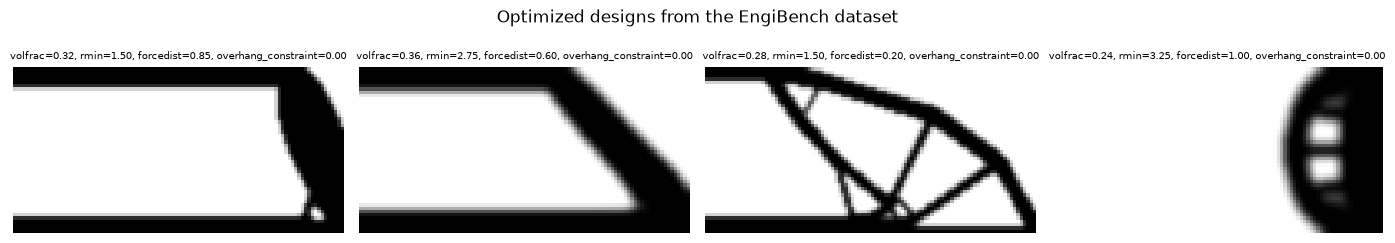

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, i in zip(axes, np.random.default_rng(SEED).choice(len(Xtr), 4, replace=False)):
    ax.imshow(Xtr[i], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(", ".join(f"{n}={v:.2f}" for n, v in zip(COND_COLS, Ctr[i])), fontsize=7)
    ax.axis("off")
plt.suptitle("Optimized designs from the EngiBench dataset"); plt.tight_layout(); plt.show()

## 3. Model: a small conditional CNN decoder, trained 5 times with different seeds

In [24]:
class Decoder(nn.Module):
    def __init__(self, n_cond, shape):
        super().__init__()
        self.shape = shape
        self.h0, self.w0 = shape[0] // 4 + 1, shape[1] // 4 + 1
        self.fc = nn.Sequential(nn.Linear(n_cond, 128), nn.GELU(), nn.Linear(128, 64 * self.h0 * self.w0), nn.GELU())
        def up(i, o):
            return nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU())
        self.net = nn.Sequential(up(64, 64), up(64, 32), nn.Conv2d(32, 1, 3, padding=1))
    def forward(self, c):
        z = self.fc(c).view(-1, 64, self.h0, self.w0)
        z = F.interpolate(self.net(z), size=self.shape, mode="bilinear", align_corners=False)
        return torch.sigmoid(z[:, 0])

def train_one(seed):
    set_seed(seed)
    m = Decoder(len(COND_COLS), SHAPE).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=CFG["LR"], weight_decay=1e-4)
    Xt, Ct = torch.tensor(Xtr), torch.tensor(norm(Ctr))
    for ep in range(CFG["EPOCHS"]):
        m.train(); perm = torch.randperm(len(Xt)); tot = 0.0
        for i in range(0, len(Xt), CFG["BATCH"]):
            b = perm[i:i + CFG["BATCH"]]
            if len(b) < 2: continue
            loss = F.binary_cross_entropy(m(Ct[b].to(DEVICE)), Xt[b].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        if ep == 0 or (ep + 1) % 10 == 0:
            print(f"  seed {seed} epoch {ep+1}/{CFG['EPOCHS']}  BCE {tot/len(Xt):.4f}")
    return m.eval()

t0 = time.time()
models = [train_one(SEED + k) for k in range(CFG["N_MODELS"])]
print(f"trained {len(models)} models in {time.time()-t0:.0f}s")

  seed 42 epoch 1/40  BCE 0.2993
  seed 42 epoch 10/40  BCE 0.1443
  seed 42 epoch 20/40  BCE 0.1386
  seed 42 epoch 30/40  BCE 0.1369
  seed 42 epoch 40/40  BCE 0.1358
  seed 43 epoch 1/40  BCE 0.3199
  seed 43 epoch 10/40  BCE 0.1444
  seed 43 epoch 20/40  BCE 0.1385
  seed 43 epoch 30/40  BCE 0.1366
  seed 43 epoch 40/40  BCE 0.1353
  seed 44 epoch 1/40  BCE 0.2995
  seed 44 epoch 10/40  BCE 0.1448
  seed 44 epoch 20/40  BCE 0.1391
  seed 44 epoch 30/40  BCE 0.1367
  seed 44 epoch 40/40  BCE 0.1357
  seed 45 epoch 1/40  BCE 0.2970
  seed 45 epoch 10/40  BCE 0.1442
  seed 45 epoch 20/40  BCE 0.1391
  seed 45 epoch 30/40  BCE 0.1366
  seed 45 epoch 40/40  BCE 0.1356
  seed 46 epoch 1/40  BCE 0.2914
  seed 46 epoch 10/40  BCE 0.1453
  seed 46 epoch 20/40  BCE 0.1386
  seed 46 epoch 30/40  BCE 0.1367
  seed 46 epoch 40/40  BCE 0.1355
trained 5 models in 855s


## 4. Generate designs for held-out conditions and simulate them

In [25]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(Xte), size=min(CFG["N_EVAL"], len(Xte)), replace=False)
Ce, Xgt = Cte[idx], Xte[idx]

with torch.no_grad():
    ct = torch.tensor(norm(Ce)).to(DEVICE)
    preds = np.stack([m(ct).cpu().numpy() for m in models])   # (models, N, H, W)
Xgen = preds[0]                                    # the design we would actually use: model 0
disagree = preds.std(0).mean(axis=(1, 2))          # warning signal 1: ensemble disagreement
D = np.sqrt(((norm(Ce)[:, None, :] - norm(Ctr)[None, :, :]) ** 2).sum(-1))
dists = np.sort(D, axis=1)[:, :10].mean(1)        # signal 2: mean distance to the 10 nearest training conditions

def config_of(c):
    cfg = {}
    for n, v in zip(COND_COLS, c):
        default = COND_DEFAULTS.get(n)
        cfg[n] = bool(v > 0.5) if isinstance(default, (bool, np.bool_)) else float(v)
    return cfg

def simulate(design, cfg):
    # Fresh simulator for every call: Beams2D caches its load/stiffness setup after the first
    # simulate(), so reusing one instance would apply the FIRST condition's load to every design.
    p = Beams2D(seed=SEED)
    out = p.simulate(design=np.asarray(design, dtype=np.float64), config=cfg)
    return float(np.asarray(out).ravel()[0])

# Sanity check: the simulator must reproduce the compliance stored in the dataset
for j in range(3):
    row = test_ds[j]
    cfg_j = {c: row[c] for c in COND_COLS}
    x_j = np.asarray(row[DESIGN_COL], dtype=np.float64).reshape(SHAPE)
    print(f"check row {j}: stored c {row['c']:.4g} | simulated {simulate(x_j, cfg_j):.4g}")

rows = []; t0 = time.time()
for i in range(len(idx)):
    cfg = config_of(Ce[i])
    viol = problem.check_constraints(design=np.asarray(Xgen[i], dtype=np.float64), config=cfg)
    c_gen = simulate(Xgen[i], cfg)
    c_gt = simulate(Xgt[i], cfg)
    rows.append(dict(**{n: float(v) for n, v in zip(COND_COLS, Ce[i])},
                     c_gen=c_gen, c_gt=c_gt, gap=(c_gen - c_gt) / abs(c_gt),
                     violated=bool(viol),
                     vol_err=float(Xgen[i].mean() - Xgt[i].mean()),
                     disagree=float(disagree[i]), nn_dist=float(dists[i])))
    if i == 0 or (i + 1) % 50 == 0:
        print(f"  simulated {i+1}/{len(idx)} ({time.time()-t0:.0f}s)")
R = pd.DataFrame(rows)
R.to_csv("results/per_condition.csv", index=False)
R.describe().round(3)

check row 0: stored c 22.94 | simulated 22.94
check row 1: stored c 30.91 | simulated 30.91
check row 2: stored c 63.35 | simulated 63.35
  simulated 1/243 (0s)
  simulated 50/243 (21s)
  simulated 100/243 (46s)
  simulated 150/243 (66s)
  simulated 200/243 (85s)


,volfrac,rmin,forcedist,overhang_constraint,c_gen,c_gt,gap,vol_err,disagree,nn_dist
count,243.000,243.000,243.000,243.0,243.000,243.000,243.000,243.000,243.000,243.000
mean,0.275,2.643,0.471,0.0,115.307,105.297,0.076,-0.003,0.010,0.252
std,0.077,0.767,0.312,0.0,119.628,108.694,0.197,0.004,0.004,0.022
min,0.150,1.500,0.000,0.0,9.694,9.825,-0.126,-0.015,0.004,0.224
25%,0.200,2.000,0.200,0.0,23.021,22.981,0.016,-0.005,0.007,0.235
50%,0.275,2.750,0.450,0.0,74.150,66.267,0.038,-0.004,0.009,0.250
75%,0.338,3.250,0.750,0.0,158.694,145.800,0.075,-0.002,0.012,0.263
max,0.400,4.000,1.000,0.0,854.427,836.635,1.962,0.011,0.022,0.328


## 5. Where does it fail?

In [26]:
def boot_ci(v, n=5000, seed=SEED):
    v = np.asarray(v, float); m = np.random.default_rng(seed).choice(v, (n, len(v))).mean(1)
    return v.mean(), np.quantile(m, .025), np.quantile(m, .975)

g = R.gap.values
m, lo, hi = boot_ci(g)
print(f"Compliance gap vs optimized design (positive = worse):")
print(f"  mean {100*m:.1f}% [95% CI {100*lo:.1f}–{100*hi:.1f}] | median {100*np.median(g):.1f}%")
print(f"  90th percentile {100*np.quantile(g,.9):.1f}% | worst {100*g.max():.1f}%")
print(f"  designs violating a constraint: {R.violated.mean()*100:.1f}%")
print(f"  designs that beat the optimizer (gap < 0): {(g<0).mean()*100:.1f}%  (often by using more material: see vol_err)")
print(f"  mean volume-fraction error: {R.vol_err.mean():+.3f}")

Compliance gap vs optimized design (positive = worse):
  mean 7.6% [95% CI 5.5–10.3] | median 3.8%
  90th percentile 14.4% | worst 196.2%
  designs violating a constraint: 2.1%
  designs that beat the optimizer (gap < 0): 8.6%  (often by using more material: see vol_err)
  mean volume-fraction error: -0.003


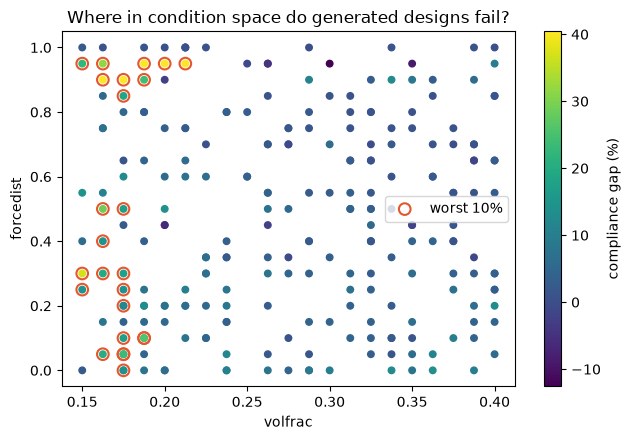


Mean gap by volfrac quartile:
_bin
(0.149, 0.2]      18.0
(0.2, 0.275]       5.2
(0.275, 0.338]     3.1
(0.338, 0.4]       3.3

Mean gap by rmin quartile:
_bin
(1.499, 2.0]    12.1
(2.0, 2.75]      5.2
(2.75, 3.25]     5.4
(3.25, 4.0]      5.5

Mean gap by forcedist quartile:
_bin
(-0.001, 0.2]     7.8
(0.2, 0.45]       5.2
(0.45, 0.75]      3.8
(0.75, 1.0]      14.8

Mean gap by overhang_constraint:
overhang_constraint
0.0    7.6


In [27]:
xc = "volfrac" if "volfrac" in COND_COLS else COND_COLS[0]
yc = "forcedist" if "forcedist" in COND_COLS else COND_COLS[1]
worst = R.gap >= R.gap.quantile(1 - CFG["WORST_FRAC"])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc = ax.scatter(R[xc], R[yc], c=100 * R.gap.clip(upper=R.gap.quantile(.98)), cmap="viridis", s=22)
ax.scatter(R.loc[worst, xc], R.loc[worst, yc], facecolors="none", edgecolors="#E4572E", s=70, lw=1.5, label=f"worst {int(100*CFG['WORST_FRAC'])}%")
plt.colorbar(sc, label="compliance gap (%)"); ax.set_xlabel(xc); ax.set_ylabel(yc); ax.legend()
ax.set_title("Where in condition space do generated designs fail?")
plt.tight_layout(); plt.savefig("results/failure_map.png", dpi=150); plt.show()

for c in COND_COLS:
    if R[c].nunique() > 4:
        R["_bin"] = pd.qcut(R[c], 4, duplicates="drop")
        print(f"\nMean gap by {c} quartile:"); print((100 * R.groupby("_bin", observed=True).gap.mean()).round(1).to_string())
    else:
        print(f"\nMean gap by {c}:"); print((100 * R.groupby(c).gap.mean()).round(1).to_string())
R = R.drop(columns="_bin", errors="ignore")

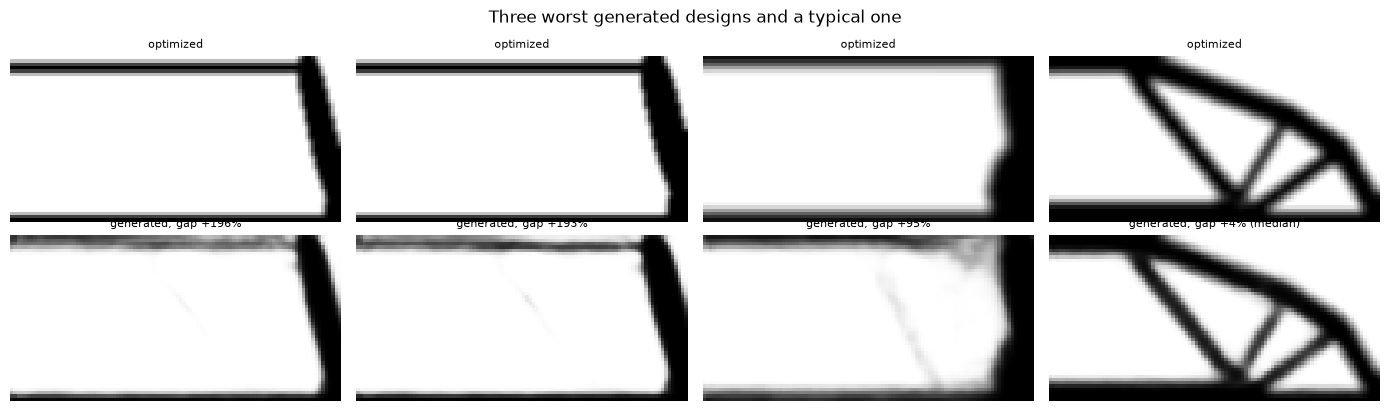

In [28]:
order = np.argsort(-R.gap.values)
show = list(order[:3]) + list(order[len(order)//2:len(order)//2 + 1])
fig, axes = plt.subplots(2, 4, figsize=(14, 4.2))
for j, i in enumerate(show):
    axes[0, j].imshow(Xgt[i], cmap="gray_r", vmin=0, vmax=1); axes[0, j].axis("off")
    axes[0, j].set_title("optimized", fontsize=8)
    axes[1, j].imshow(Xgen[i], cmap="gray_r", vmin=0, vmax=1); axes[1, j].axis("off")
    axes[1, j].set_title(f"generated, gap {100*R.gap.iloc[i]:+.0f}%" + (" (median)" if j == 3 else ""), fontsize=8)
plt.suptitle("Three worst generated designs and a typical one"); plt.tight_layout()
plt.savefig("results/worst_designs.png", dpi=150); plt.show()

## 6. Can we see failures coming, before simulating?

A failure = a design in the worst 10% of compliance gap. AUROC 0.5 = no better than chance, 1.0 = perfect warning.

ensemble disagreement                    AUROC 0.72 [95% CI 0.63–0.80] | Spearman with gap +0.44
distance to 10 nearest training conditions AUROC 0.50 [95% CI 0.39–0.62] | Spearman with gap +0.04

Keep the 80% lowest-disagreement designs: mean gap 5.4% vs 7.6% overall; worst-10% designs caught in the flagged 20%: 36%


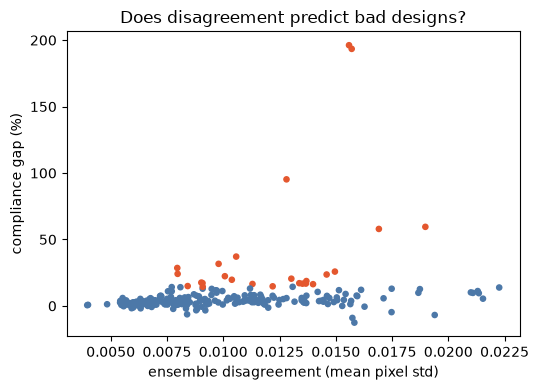

In [29]:
y_fail = worst.values.astype(int)
signals = {"ensemble disagreement": R.disagree.values, "distance to 10 nearest training conditions": R.nn_dist.values}
res = {}
for name, s in signals.items():
    auc = roc_auc_score(y_fail, s)
    b = np.random.default_rng(SEED); boots = []
    for _ in range(2000):
        k = b.integers(0, len(s), len(s))
        if y_fail[k].min() != y_fail[k].max():
            boots.append(roc_auc_score(y_fail[k], s[k]))
    lo, hi = np.quantile(boots, [.025, .975])
    rho = pd.Series(s).corr(R.gap, method="spearman")
    res[name] = dict(auroc=auc, lo=lo, hi=hi, spearman=rho)
    print(f"{name:<40s} AUROC {auc:.2f} [95% CI {lo:.2f}–{hi:.2f}] | Spearman with gap {rho:+.2f}")

# What if we only trusted the 80% most confident designs?
keep = R.disagree <= R.disagree.quantile(0.8)
print(f"\nKeep the 80% lowest-disagreement designs: mean gap {100*R.gap[keep].mean():.1f}% vs {100*R.gap.mean():.1f}% overall; "
      f"worst-10% designs caught in the flagged 20%: {100*worst[~keep].sum()/worst.sum():.0f}%")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(R.disagree, 100 * R.gap, s=14, c=np.where(worst, "#E4572E", "#4C78A8"))
ax.set_xlabel("ensemble disagreement (mean pixel std)"); ax.set_ylabel("compliance gap (%)")
ax.set_title("Does disagreement predict bad designs?")
plt.tight_layout(); plt.savefig("results/disagreement_vs_gap.png", dpi=150); plt.show()

## 7. Save results

In [30]:
summary = dict(
    config=CFG, n_train=int(len(Xtr)), n_eval=int(len(R)), shape=list(SHAPE), conditions=COND_COLS,
    gap=dict(zip(["mean", "lo", "hi"], map(float, boot_ci(R.gap.values)))),
    gap_median=float(R.gap.median()), gap_p90=float(R.gap.quantile(.9)), gap_max=float(R.gap.max()),
    violation_rate=float(R.violated.mean()), vol_err_mean=float(R.vol_err.mean()),
    warning_signals={k: {kk: float(vv) for kk, vv in v.items()} for k, v in res.items()},
)
json.dump(summary, open("results/summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "config": {
    "N_MODELS": 5,
    "EPOCHS": 40,
    "BATCH": 64,
    "LR": 0.001,
    "N_EVAL": 400,
    "WORST_FRAC": 0.1,
    "QUICK": false
  },
  "n_train": 3880,
  "n_eval": 243,
  "shape": [
    50,
    100
  ],
  "conditions": [
    "volfrac",
    "rmin",
    "forcedist",
    "overhang_constraint"
  ],
  "gap": {
    "mean": 0.07620184482644675,
    "lo": 0.05469444681866689,
    "hi": 0.10293177825061227
  },
  "gap_median": 0.03766721100733688,
  "gap_p90": 0.14383814421630636,
  "gap_max": 1.9618634056247641,
  "violation_rate": 0.0205761316872428,
  "vol_err_mean": -0.00330651480965163,
  "warning_signals": {
    "ensemble disagreement": {
      "auroc": 0.7168807339449541,
      "lo": 0.6297223921168875,
      "hi": 0.7963420420453063,
      "spearman": 0.4421788676632193
    },
    "distance to 10 nearest training conditions": {
      "auroc": 0.5037614678899083,
      "lo": 0.38803905381214576,
      "hi": 0.6150310400751521,
      "spearman": 0.04228569762988311
   

## Notes and limitations
- One problem (Beams2D, 100×50), one deliberately simple generator; no hyperparameter tuning. EngiOpt's stronger generators (cGAN-CNN, conditional diffusion) are the natural next comparison.
- "Gap" compares one generated design to the dataset's optimized design for the same condition; designs with too much material can beat the optimizer, so the volume-fraction error and constraint check are reported alongside.
- Next steps: same per-condition analysis for EngiOpt's models; use disagreement to decide when to fall back to the optimizer (warm-start only flagged designs); repeat on a second EngiBench problem.